In [7]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

# =====================================================
# 1. CONFIGURATION
# =====================================================

CSV_PATH = "Dataset/hybrid_manufacturing_categorical.csv"
DATASET_DIR = Path("dataset")
DATASET_DIR.mkdir(exist_ok=True)

TRAIN_END = 400
STABLE = (400, 600)
DRIFT = (600, 800)
RECOVERY = (800, None)

MULT_DRIFT = 1.6
MULT_RECOVERY = 1.15

FEATURES = [
    "Processing_Time",
    "Energy_Consumption",
    "Machine_Availability",
    "Upstream_Lag",
    "Station_ID"
]


# =====================================================
# 2. LOAD DATASET
# =====================================================

def load_dataset(csv_path=CSV_PATH):
    df = pd.read_csv(csv_path)

    assert df.shape == (1000, 13), (
        f"Unexpected dataset shape: {df.shape}"
    )

    return df


# =====================================================
# 3. FEATURE ENGINEERING
# =====================================================

def create_features(df):
    df = df.copy()

    df["Station_ID"] = pd.factorize(
        df["Machine_ID"]
    )[0]

    df["Upstream_Lag"] = (
        df.groupby("Machine_ID")["Processing_Time"]
        .shift(1)
    )

    df = df.dropna(
        subset=["Upstream_Lag"]
    ).reset_index(drop=True)

    assert len(df) == 995, (
        f"Unexpected number of rows: {len(df)}"
    )

    return df


# =====================================================
# 4. SIMULATE CONCEPT DRIFT
# =====================================================

def simulate_drift(df):
    df = df.copy()

    df["PT_orig"] = df["Processing_Time"].astype(float)

    mult = np.ones(len(df))

    mult[DRIFT[0]:DRIFT[1]] = MULT_DRIFT
    mult[RECOVERY[0]:] = MULT_RECOVERY

    df["mult"] = mult

    df["Processing_Time"] = df["PT_orig"] * mult
    df["Upstream_Lag"] = df["Upstream_Lag"] * mult

    df["phase"] = "train"

    df.loc[
        STABLE[0]:STABLE[1]-1, "phase"
    ] = "stable"

    df.loc[
        DRIFT[0]:DRIFT[1]-1, "phase"
    ] = "drift"

    df.loc[
        RECOVERY[0]:, "phase"
    ] = "recovery"

    return df


# =====================================================
# 5. PREPARE MODEL FEATURES
# =====================================================

def prepare_features(df):
    Xraw = df[FEATURES].to_numpy(float)

    yraw = df["Processing_Time"].to_numpy(float)

    return Xraw, yraw


# =====================================================
# 6. SAVE PREPARED DATA USING JOBLIB
# =====================================================

def save_prepared_data(df, Xraw, yraw):

    data = {
        "df": df,
        "Xraw": Xraw,
        "yraw": yraw,
        "features": FEATURES,
        "train_end": TRAIN_END,
        "stable": STABLE,
        "drift": DRIFT,
        "recovery": RECOVERY,
        "window": 10,
        "drift_multiplier": MULT_DRIFT,
        "recovery_multiplier": MULT_RECOVERY
    }

    output_path = DATASET_DIR / "cycle_time_data.joblib"

    joblib.dump(data, output_path)

    return output_path


# =====================================================
# 7. LOAD PREPARED DATA
# =====================================================

def load_prepared_data(
    path=DATASET_DIR / "cycle_time_data.joblib"
):
    return joblib.load(path)


# =====================================================
# 8. COMPLETE PREPARATION PIPELINE
# =====================================================

def run_data_preparation():

    df = load_dataset()

    df = create_features(df)

    df = simulate_drift(df)

    Xraw, yraw = prepare_features(df)

    path = save_prepared_data(df, Xraw, yraw)

    print("Data preparation completed!")
    print("Dataset shape:", df.shape)
    print("Input shape:", Xraw.shape)
    print("Target shape:", yraw.shape)
    print("Saved to:", path)

    print("\nOperating phases:")
    print(df["phase"].value_counts())

    return df, Xraw, yraw


# =====================================================
# 9. EXECUTE
# =====================================================

df, Xraw, yraw = run_data_preparation()


Data preparation completed!
Dataset shape: (995, 18)
Input shape: (995, 5)
Target shape: (995,)
Saved to: dataset\cycle_time_data.joblib

Operating phases:
phase
train       400
stable      200
drift       200
recovery    195
Name: count, dtype: int64


In [8]:
import joblib

data = joblib.load("dataset/cycle_time_data.joblib")

df = data["df"]
Xraw = data["Xraw"]
yraw = data["yraw"]
FEATURES = data["features"]
TRAIN_END = data["train_end"]

print("Dataset loaded:", df.shape)
print("Features:", FEATURES)

Dataset loaded: (995, 18)
Features: ['Processing_Time', 'Energy_Consumption', 'Machine_Availability', 'Upstream_Lag', 'Station_ID']


Loaded object type: <class 'dict'>
Available keys: ['df', 'Xraw', 'yraw', 'features', 'train_end', 'stable', 'drift', 'recovery', 'window', 'drift_multiplier', 'recovery_multiplier']
Using dataset key: df
Number of observations: 995
Missing processing times: 0


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


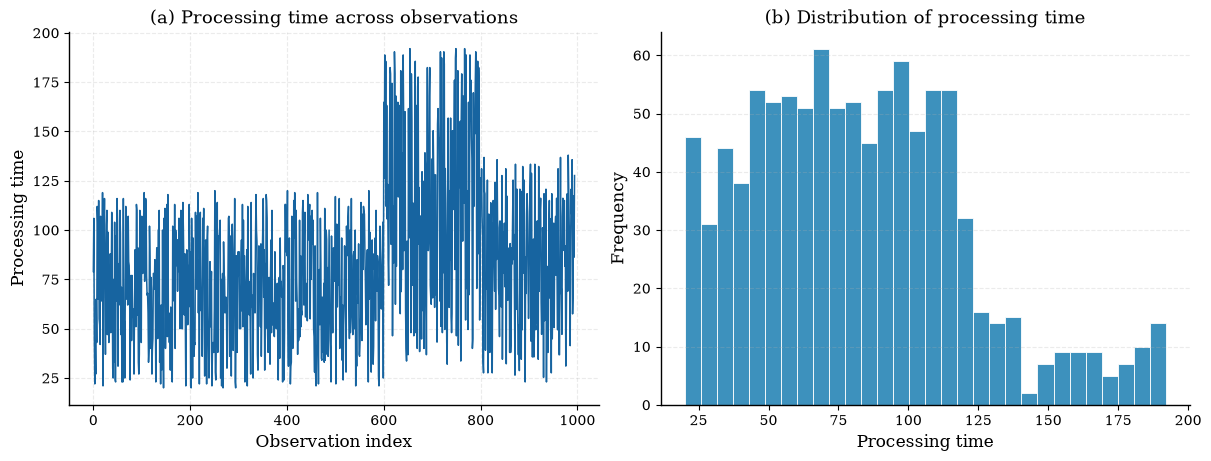

EPS saved: Figures/manufacturing_dataset_overview.eps
PNG saved: Figures/manufacturing_dataset_overview.png
PDF saved: Figures/manufacturing_dataset_overview.pdf


In [1]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. Load manufacturing dataset
# ==========================================

dataset_path = "Dataset/cycle_time_data.joblib"
data = joblib.load(dataset_path)

print("Loaded object type:", type(data))

# Inspect the saved object
if isinstance(data, dict):
    print("Available keys:", list(data.keys()))
else:
    print("Shape:", np.shape(data))

# ==========================================
# 2. Extract processing time
# ==========================================

if isinstance(data, pd.DataFrame):
    df = data.copy()

elif isinstance(data, dict):
    # Prefer original, unmodified data if available
    for key in ["original_df", "raw_df", "df", "data"]:
        if key in data and isinstance(data[key], pd.DataFrame):
            df = data[key].copy()
            print("Using dataset key:", key)
            break
    else:
        raise ValueError(
            "No DataFrame found. Inspect the keys printed above."
        )
else:
    raise TypeError(
        "Unsupported dataset structure. Inspect the loaded object."
    )

# Support common column naming conventions
possible_columns = [
    "Processing_Time",
    "Processing time",
    "Processing Time",
    "processing_time"
]

processing_col = next(
    (c for c in possible_columns if c in df.columns),
    None
)

if processing_col is None:
    raise ValueError(
        f"Processing time column not found. Columns: {df.columns.tolist()}"
    )

processing_time = pd.to_numeric(
    df[processing_col], errors="coerce"
)

print("Number of observations:", len(processing_time))
print("Missing processing times:", processing_time.isna().sum())

# ==========================================
# 3. Publication-quality settings
# ==========================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.0,
    "savefig.dpi": 1200,
    "ps.fonttype": 42,
    "pdf.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False
})

os.makedirs("Figures", exist_ok=True)

# ==========================================
# 4. Create two-panel figure
# ==========================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    constrained_layout=True
)

# Panel (a): Processing time over observations
axes[0].plot(
    np.arange(len(processing_time)),
    processing_time,
    color="#1764A0",
    linewidth=1.1
)

axes[0].set_xlabel("Observation index")
axes[0].set_ylabel("Processing time")
axes[0].set_title("(a) Processing time across observations")
axes[0].grid(
    True, linestyle="--", alpha=0.25
)

# Panel (b): Processing time distribution
axes[1].hist(
    processing_time.dropna(),
    bins=30,
    color="#3D91BD",
    edgecolor="white",
    linewidth=0.6
)

axes[1].set_xlabel("Processing time")
axes[1].set_ylabel("Frequency")
axes[1].set_title("(b) Distribution of processing time")
axes[1].grid(
    True, axis="y",
    linestyle="--", alpha=0.25
)

# ==========================================
# 5. Export high-quality figures
# ==========================================

eps_path = "Figures/manufacturing_dataset_overview.eps"
png_path = "Figures/manufacturing_dataset_overview.png"
pdf_path = "Figures/manufacturing_dataset_overview.pdf"

fig.savefig(
    eps_path,
    format="eps",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    png_path,
    format="png",
    dpi=1200,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("EPS saved:", eps_path)
print("PNG saved:", png_path)
print("PDF saved:", pdf_path)


Loaded object type: <class 'dict'>
Available keys: ['df', 'Xraw', 'yraw', 'features', 'train_end', 'stable', 'drift', 'recovery', 'window', 'drift_multiplier', 'recovery_multiplier']
Using dataset key: df
Total observations: 995
Missing values: 0


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


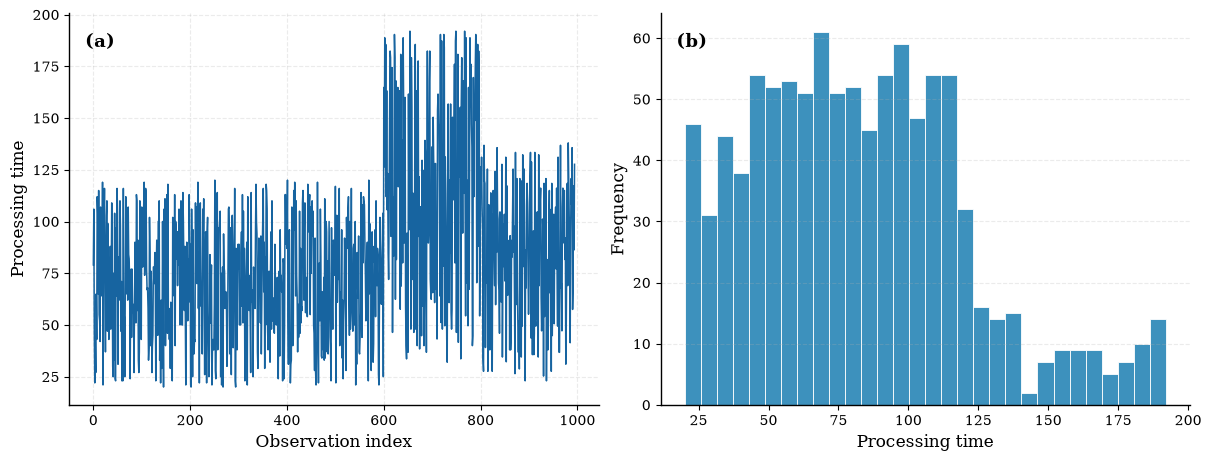

Figure saved successfully:
figure/Figure1_manufacturing_dataset_overview.eps


In [2]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# 1. Load manufacturing dataset
# =====================================================

dataset_path = "Dataset/cycle_time_data.joblib"
data = joblib.load(dataset_path)

print("Loaded object type:", type(data))

if isinstance(data, pd.DataFrame):
    df = data.copy()

elif isinstance(data, dict):
    print("Available keys:", list(data.keys()))

    # Prefer original data if present
    for key in ["original_df", "raw_df", "df", "data"]:
        if key in data and isinstance(data[key], pd.DataFrame):
            df = data[key].copy()
            print("Using dataset key:", key)
            break
    else:
        raise ValueError(
            "No DataFrame found. Inspect the available keys."
        )
else:
    raise TypeError("Unsupported dataset format.")

# =====================================================
# 2. Extract processing time
# =====================================================

possible_columns = [
    "Processing_Time",
    "Processing time",
    "Processing Time",
    "processing_time"
]

processing_col = next(
    (col for col in possible_columns if col in df.columns),
    None
)

if processing_col is None:
    raise ValueError(
        f"Processing time column not found. "
        f"Available columns: {df.columns.tolist()}"
    )

processing_time = pd.to_numeric(
    df[processing_col],
    errors="coerce"
)

print("Total observations:", len(processing_time))
print("Missing values:", processing_time.isna().sum())

# =====================================================
# 3. Publication-quality figure settings
# =====================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.0,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# =====================================================
# 4. Generate Figure 1
# =====================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    constrained_layout=True
)

# (a) Processing time across observations
axes[0].plot(
    np.arange(len(processing_time)),
    processing_time,
    color="#1764A0",
    linewidth=1.1
)

axes[0].set_xlabel("Observation index")
axes[0].set_ylabel("Processing time")
axes[0].grid(
    True,
    linestyle="--",
    alpha=0.25
)

# Panel label (a)
axes[0].text(
    0.03, 0.95, "(a)",
    transform=axes[0].transAxes,
    fontsize=13,
    fontweight="bold",
    va="top"
)

# (b) Processing time distribution
axes[1].hist(
    processing_time.dropna(),
    bins=30,
    color="#3D91BD",
    edgecolor="white",
    linewidth=0.6
)

axes[1].set_xlabel("Processing time")
axes[1].set_ylabel("Frequency")
axes[1].grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.25
)

# Panel label (b)
axes[1].text(
    0.03, 0.95, "(b)",
    transform=axes[1].transAxes,
    fontsize=13,
    fontweight="bold",
    va="top"
)

# =====================================================
# 5. Save EPS only (same Figure 1 filename)
# =====================================================

os.makedirs("figure", exist_ok=True)

output_path = (
    "figure/Figure1_manufacturing_dataset_overview.eps"
)

fig.savefig(
    output_path,
    format="eps",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved successfully:")
print(output_path)


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


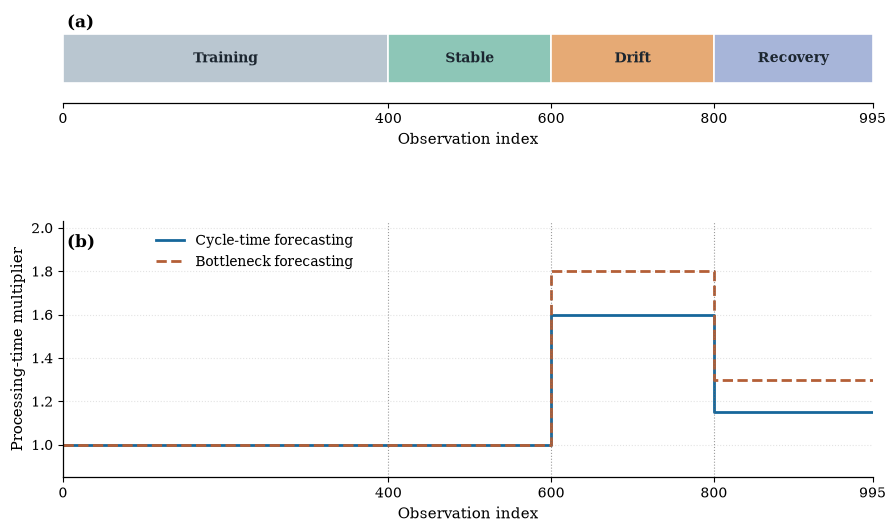

Saved: C:\Users\himatsha\python_code\Behzad\python_code\datasetandcodereport\B_V1\figure\Figure2_simulated_operating_phases.eps
Note: machine availability is not plotted because its recovery multiplier is unconfirmed.


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Reproducible schematic of the experimental settings.
# No actual observations are plotted in this figure.
plt.rcParams.update({
    'font.family': 'serif', 'font.size': 11, 'axes.labelsize': 11,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'axes.linewidth': 0.9, 'ps.fonttype': 42,
    'pdf.fonttype': 42, 'savefig.facecolor': 'white'
})

phases = ['Training', 'Stable', 'Drift', 'Recovery']
starts = [0, 400, 600, 800]
ends = [400, 600, 800, 995]
colors = ['#B9C6D0', '#8DC6B7', '#E6AA75', '#A7B5D9']

fig, axes = plt.subplots(2, 1, figsize=(9.2, 5.5),
                         gridspec_kw={'height_ratios': [0.8, 2.2]})
ax = axes[0]
for name, left, right, color in zip(phases, starts, ends, colors):
    ax.barh(0, right-left, left=left, height=0.42,
            color=color, edgecolor='white', linewidth=1.2)
    ax.text((left+right)/2, 0, name, ha='center', va='center',
            fontsize=10, fontweight='bold', color='#1C2630')
ax.set_xlim(0, 995)
ax.set_ylim(-0.38, 0.42)
ax.set_yticks([])
ax.set_xticks([0, 400, 600, 800, 995])
ax.set_xlabel('Observation index')
ax.text(0.005, 0.95, '(a)', transform=ax.transAxes,
        ha='left', va='top', fontweight='bold', fontsize=12)
for side in ['left','right','top']:
    ax.spines[side].set_visible(False)

ax = axes[1]
cycle = [1.0, 1.0, 1.6, 1.15]
bottleneck = [1.0, 1.0, 1.8, 1.30]
# Piecewise-constant settings; this is not the observed processing-time series.
for vals, label, color, style in [
    (cycle, 'Cycle-time forecasting', '#16679B', '-'),
    (bottleneck, 'Bottleneck forecasting', '#B45F37', '--')
]:
    xx = [0, 400, 600, 800, 995]
    yy = vals + [vals[-1]]
    ax.step(xx, yy, where='post', linewidth=2.0,
            linestyle=style, color=color, label=label)
for x in [400, 600, 800]:
    ax.axvline(x, color='#666666', linestyle=':', linewidth=0.8, alpha=0.65)
ax.set_xlim(0, 995)
ax.set_ylim(0.85, 2.03)
ax.set_xticks([0, 400, 600, 800, 995])
ax.set_xlabel('Observation index')
ax.set_ylabel('Processing-time multiplier')
ax.grid(axis='y', linestyle=':', alpha=0.35)
ax.legend(loc='upper left', bbox_to_anchor=(0.10, 1.00),
          frameon=False, fontsize=10)
ax.text(0.005, 0.95, '(b)', transform=ax.transAxes,
        ha='left', va='top', fontweight='bold', fontsize=12)
for side in ['top','right']:
    ax.spines[side].set_visible(False)

fig.subplots_adjust(hspace=0.68, left=0.10, right=0.98, top=0.97, bottom=0.12)
os.makedirs('figure', exist_ok=True)
out = 'figure/Figure2_simulated_operating_phases.eps'
fig.savefig(out, format='eps', bbox_inches='tight')
plt.show()
print('Saved:', os.path.abspath(out))
print('Note: machine availability is not plotted because its recovery multiplier is unconfirmed.')
